# Defending the Krone
**Can exchange-market pressure predict Danmarks Nationalbank's unilateral interest-rate decisions?**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gabsmm18/defending-the-krone/blob/main/notebooks/defending_the_krone.ipynb)

Mattia Mariani, MSc Applied Economics and Finance, Copenhagen Business School

---

**Research question.** Denmark has pegged the krone to the euro since 1999, so Danmarks Nationalbank normally mirrors the ECB's rate decisions. When the krone comes under pressure, it first intervenes in the foreign-exchange market and, if pressure persists, changes its policy rate *unilaterally*. This notebook asks whether observable pressure on the krone, namely the position of EUR/DKK relative to the central rate and the Nationalbank's own interventions, predicts these unilateral moves, and whether that predictability could be exploited in Danish short-term rates.

**Outline**
1. Background: the Danish fixed exchange-rate policy
2. Data
3. Identifying unilateral rate moves
4. An exchange-market pressure index
5. Does pressure predict the Nationalbank?
6. A stylised rates trade
7. Current reading
8. Limitations and extensions

*Research and educational project. Not investment advice.*

**To run:** store a free FRED API key as a Colab secret named `FRED_API_KEY` (key icon in the left sidebar), then `Runtime → Run all`. The Danish data come from the Statistics Denmark API, which requires no key.

## 1. Background: the Danish fixed exchange-rate policy

**The peg.** Denmark participates in ERM II with a central rate of 7.46038 kroner per euro and a formal fluctuation band of ±2.25%. In practice, the Nationalbank keeps the krone far closer to the central rate than the band allows. Monetary policy has a single objective, the exchange rate, and there is no independent inflation target.

**The reaction function.** In normal times, the Nationalbank changes its rates when the ECB does, keeping the *policy spread* (Danish rate minus ECB rate) constant. Under pressure, it uses two instruments in sequence:
1. **Foreign-exchange intervention.** When the krone is strong, it sells kroner and buys foreign exchange; when it is weak, it does the opposite, drawing on its foreign-exchange reserve.
2. **Unilateral rate changes.** If interventions are large or persistent, it changes the policy spread: a *cut* to discourage inflows when the krone is too strong, a *hike* to defend it when it is too weak.

**Why this is predictable in principle.** Unlike an inflation-targeting central bank, the Nationalbank's reaction function is narrow and largely observable. Pressure shows up first in the exchange rate and in interventions, which are published monthly, before any rate decision. The Nationalbank's own research finds that its interventions are effective in moving the exchange rate (Danmarks Nationalbank, 2016).

**Measuring pressure.** The exchange-market pressure (EMP) literature (Girton & Roper, 1977; Eichengreen, Rose & Wyplosz, 1996) combines exchange-rate movements, reserve changes and interest-rate changes into a single index of pressure on a currency. Under a hard peg the exchange rate barely moves, so pressure is absorbed mainly by interventions and, eventually, by interest rates. Here the interest-rate component is excluded from the index, because it is precisely the outcome to be predicted.

## 2. Data

| Series | Source | Code | Frequency |
|---|---|---|---|
| Nationalbank rate on certificates of deposit (monetary policy deposit rate) | Statistics Denmark | `DNRENTD` / `OIBNAA` | Daily → month-end |
| Nationalbank FX interventions, net purchase of foreign exchange (DKK bn) | Statistics Denmark | `DNSNB2` / `N7A` | Monthly |
| EUR/DKK, computed as DKK per USD × USD per EUR | FRED | `DEXDNUS`, `DEXUSEU` | Daily → month-end |
| ECB main refinancing rate and deposit facility rate | FRED | `ECBMRRFR`, `ECBDFR` | Daily → month-end |

**ECB main refinancing rate.** FRED's `ECBMRRFR` covers fixed-rate tenders only, so it does not move during the ECB's variable-rate tender period (June 2000 to October 2008). Over that period the ECB's rate corridor was symmetric, with the main refinancing rate one percentage point above the deposit facility rate, so the main refinancing rate is reconstructed as the deposit rate plus one point until 8 October 2008.

**Policy spread.** The Nationalbank rate is compared with the ECB main refinancing rate until May 2014, and with the ECB deposit facility rate from June 2014 onwards, when ample excess liquidity made the deposit rate the effective anchor of euro money-market rates. Since March 2021, the Nationalbank's current-account and certificate-of-deposit rates have been identical.

In [1]:
import io
import json
import os
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'grid.alpha': 0.3})
pd.set_option('display.float_format', '{:.3f}'.format)

In [2]:
CENTRAL_RATE = 7.46038          # ERM II central rate, DKK per EUR
BAND = 2.25                     # ERM II fluctuation band, +-%
ECB_REF_SWITCH = "2014-06"      # before: compare with ECB MRO rate; from then: deposit facility rate
# FRED's ECBMRRFR covers fixed-rate tenders only, so it is flat during the variable-rate tender
# period (June 2000 - October 2008). Before 9 Oct 2008 the ECB corridor was symmetric
# (MRO = deposit rate + 1pp), so the MRO is reconstructed from the deposit facility rate.
MRO_FIXED_RATE_FROM = "2008-10-15"
MRO_FROM_DFR_UNTIL = "2008-10-08"
MIN_PERSISTENCE_DAYS = 10       # spread changes reversed within this window are timing mismatches
# Technical adjustment of the Nationalbank's instruments (19 March 2021): the CD rate rose
# from -0.60% to -0.50% while the current-account rate fell; not a change in the policy stance.
TECHNICAL_DATES = [("2021-03-15", "2021-03-25")]

STATBANK_URL = "https://api.statbank.dk/v1/data/{table}/CSV?lang=en&valuePresentation=Code&{query}"

FRED_CSV_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={}"
FRED_API_URL = ("https://api.stlouisfed.org/fred/series/observations"
                "?series_id={}&api_key={}&file_type=json")
FRED_API_KEY = os.environ.get("FRED_API_KEY", "")


def _http_get(url: str, timeout: int = 90) -> str:
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return resp.read().decode("utf-8")


def _retry(fn, retries: int = 3):
    last = None
    for attempt in range(retries):
        try:
            return fn()
        except Exception as e:
            last = e
            time.sleep(2 * (attempt + 1))
    raise RuntimeError(str(last))


def fetch_fred(series_id: str) -> pd.Series:
    """One FRED series (official API if FRED_API_KEY is set, else keyless CSV)."""
    def go():
        if FRED_API_KEY:
            obs = json.loads(_http_get(FRED_API_URL.format(series_id, FRED_API_KEY)))["observations"]
            s = pd.Series({pd.Timestamp(o["date"]): o["value"] for o in obs})
        else:
            df = pd.read_csv(io.StringIO(_http_get(FRED_CSV_URL.format(series_id))),
                             index_col=0, parse_dates=True)
            s = df.iloc[:, 0]
        s = pd.to_numeric(s.replace(".", np.nan), errors="coerce").dropna().sort_index()
        s.name = series_id
        return s
    return _retry(go)


def _parse_statbank_time(t: pd.Series) -> pd.DatetimeIndex:
    t = t.astype(str)
    if t.str.contains("D").any():                                   # daily: 2015M01D15
        return pd.to_datetime(t.str.replace("M", "-").str.replace("D", "-"), format="%Y-%m-%d")
    return pd.to_datetime(t.str.replace("M", "-") + "-01", format="%Y-%m-%d")   # monthly: 2015M01


def fetch_statbank(table: str, **filters) -> pd.Series:
    """
    One series from the Statistics Denmark Statbank API.
    `filters` select one value per variable, e.g. INSTRUMENT="OIBNAA", OPGOER="E".
    """
    query = "&".join([f"{k}={v}" for k, v in filters.items()] + ["Tid=*"])

    def go():
        raw = _http_get(STATBANK_URL.format(table=table, query=query))
        df = pd.read_csv(io.StringIO(raw), sep=";", dtype=str)
        val = pd.to_numeric(df["INDHOLD"].str.replace(",", "."), errors="coerce")
        s = pd.Series(val.values, index=_parse_statbank_time(df["TID"])).dropna().sort_index()
        s.name = table
        return s
    return _retry(go)


def _month_end(s: pd.Series) -> pd.Series:
    return s.groupby(s.index.to_period("M")).last()


def mro_equivalent(ecb_mro: pd.Series, ecb_dfr: pd.Series) -> pd.Series:
    """Daily MRO: deposit rate + 1pp until 8 Oct 2008, FRED fixed-rate MRO from 15 Oct 2008."""
    days = pd.date_range(min(ecb_mro.index.min(), ecb_dfr.index.min()),
                         max(ecb_mro.index.max(), ecb_dfr.index.max()), freq="D")
    dfr_d = ecb_dfr.reindex(days).ffill()
    early = (dfr_d + 1.0).loc[:MRO_FROM_DFR_UNTIL]
    late = ecb_mro.loc[MRO_FIXED_RATE_FROM:]
    return pd.concat([early, late]).sort_index().reindex(days).ffill()


def daily_unilateral_moves(dn: pd.Series, ecb_mro: pd.Series, ecb_dfr: pd.Series) -> pd.Series:
    """
    Unilateral moves measured on DAILY data, then summed by month.

    1. On every calendar day, the unilateral change is the change in the Nationalbank rate
       minus the change in the ECB reference rate (MRO before June 2014, deposit rate after).
       Using each series' own daily change avoids an artificial jump when the reference switches.
    2. Technical adjustments of the Nationalbank's instruments are excluded.
    3. Short-lived deviations that are reversed are removed: when the Nationalbank and the
       ECB implement the same decision a few days apart (e.g. Danish +0.60 on 28 Oct 2022,
       ECB +0.75 on 2 Nov 2022), the temporary gap is removed and only the persistent
       difference (-0.15) is counted. Consecutive moves in the same direction are kept.
    """
    days = pd.date_range(dn.index.min(), max(dn.index.max(), ecb_dfr.index.max()), freq="D")
    dn_d = dn.reindex(days).ffill()
    mro_d = mro_equivalent(ecb_mro, ecb_dfr).reindex(days).ffill()
    dfr_d = ecb_dfr.reindex(days).ffill()
    use_dfr = days >= pd.Timestamp(ECB_REF_SWITCH + "-01")
    d_ecb = pd.Series(np.where(use_dfr, dfr_d.diff(), mro_d.diff()), index=days)
    d_dn = dn_d.diff()
    for a, b in TECHNICAL_DATES:
        d_dn.loc[a:b] = 0.0
    start = max(ecb_mro.index.min(), ecb_dfr.index.min(), dn.index.min())
    u = (d_dn - d_ecb).loc[start:].fillna(0.0).round(4)
    cum = u.cumsum().round(4)

    # Remove short-lived levels that are REVERSED: a level lasting less than
    # MIN_PERSISTENCE_DAYS, entered by a move in one direction and left by a move in the
    # opposite direction, is a timing mismatch with the ECB. Consecutive moves in the
    # same direction (e.g. the four cuts of 19 Jan - 5 Feb 2015) are genuine and kept.
    run_id = (cum != cum.shift()).cumsum()
    runs = cum.groupby(run_id).agg(["first", "size"])
    level, length = runs["first"].values, runs["size"].values
    transient = np.zeros(len(runs), dtype=bool)
    for k in range(1, len(runs) - 1):
        enter, leave = level[k] - level[k - 1], level[k + 1] - level[k]
        transient[k] = length[k] < MIN_PERSISTENCE_DAYS and np.sign(enter) != np.sign(leave)
    keep = pd.Series(~transient, index=runs.index).reindex(run_id.values).values
    clean = cum.where(keep).ffill().fillna(0.0)
    daily = clean.diff().fillna(0.0).round(4)
    return daily.groupby(daily.index.to_period("M")).sum().round(4)

def load_data(fetch_fred=fetch_fred, fetch_statbank=fetch_statbank, start: str = "1999-01",
              drop_incomplete_month: bool = True, verbose: bool = True) -> pd.DataFrame:
    """Monthly DataFrame: eurdkk, dev_pct, dn_rate, ecb_ref, spread, interventions."""
    eurdkk = fetch_fred("DEXDNUS") * fetch_fred("DEXUSEU")          # DKK per USD x USD per EUR
    ecb_mro, ecb_dfr = fetch_fred("ECBMRRFR"), fetch_fred("ECBDFR")
    dn = fetch_statbank("DNRENTD", INSTRUMENT="OIBNAA", OPGOER="E")    # CD rate, daily
    interv = fetch_statbank("DNSNB2", INSTRUMENT="N7A", SPECNAT="I")   # monthly, DKK bn

    df = pd.DataFrame({
        "eurdkk": _month_end(eurdkk.dropna()),
        "dn_rate": _month_end(dn),
        "ecb_mro": _month_end(mro_equivalent(ecb_mro, ecb_dfr)),
        "ecb_dfr": _month_end(ecb_dfr),
    })
    iv = interv.copy()
    iv.index = iv.index.to_period("M")
    df["interventions"] = iv.groupby(level=0).last()

    if verbose:
        print("Last available observation per series:")
        print(df.apply(lambda c: c.last_valid_index()).to_string())

    if drop_incomplete_month:
        df = df.loc[df.index < pd.Timestamp.today().to_period("M")]
    df = df.loc[df.index >= pd.Period(start, "M")]
    df[["dn_rate", "ecb_mro", "ecb_dfr"]] = df[["dn_rate", "ecb_mro", "ecb_dfr"]].ffill()

    df["unilateral"] = daily_unilateral_moves(dn, ecb_mro, ecb_dfr).reindex(df.index).fillna(0.0)

    switch = pd.Period(ECB_REF_SWITCH, "M")
    df["ecb_ref"] = np.where(df.index < switch, df["ecb_mro"], df["ecb_dfr"])
    df["spread"] = df["dn_rate"] - df["ecb_ref"]
    df["dev_pct"] = (df["eurdkk"] / CENTRAL_RATE - 1) * 100
    return df.dropna(subset=["eurdkk", "dn_rate", "ecb_ref"])

In [3]:
try:
    from google.colab import userdata          # Colab Secrets
    FRED_API_KEY = userdata.get('FRED_API_KEY') or ''
except Exception:
    pass
if not FRED_API_KEY:
    from getpass import getpass
    FRED_API_KEY = getpass("Paste your FRED API key: ").strip()
print("Using FRED API" if FRED_API_KEY else "No key: using keyless CSV (may time out on Colab)")

Paste your FRED API key: ··········
Using FRED API


In [4]:
df = load_data(fetch_fred=fetch_fred, fetch_statbank=fetch_statbank, start="1999-01")
print(f"\nSample: {df.index[0]} → {df.index[-1]}  ({len(df)} months)")
df.tail()

Last available observation per series:
eurdkk           2026-11
dn_rate          2026-11
ecb_mro          2026-11
ecb_dfr          2026-11
interventions    2026-10

Sample: 1999-01 → 2026-10  (334 months)


,eurdkk,dn_rate,ecb_mro,ecb_dfr,interventions,unilateral,ecb_ref,spread,dev_pct
2026-06,7.473,1.850,2.400,2.250,-0.748,0.000,2.250,-0.400,0.174
2026-07,7.474,1.850,2.400,2.250,0.000,0.000,2.250,-0.400,0.185
2026-08,7.475,1.850,2.400,2.250,-5.599,0.000,2.250,-0.400,0.197
2026-09,7.475,2.100,2.650,2.500,0.000,0.000,2.500,-0.400,0.196
2026-10,7.473,2.100,2.650,2.500,0.000,0.000,2.500,-0.400,0.172


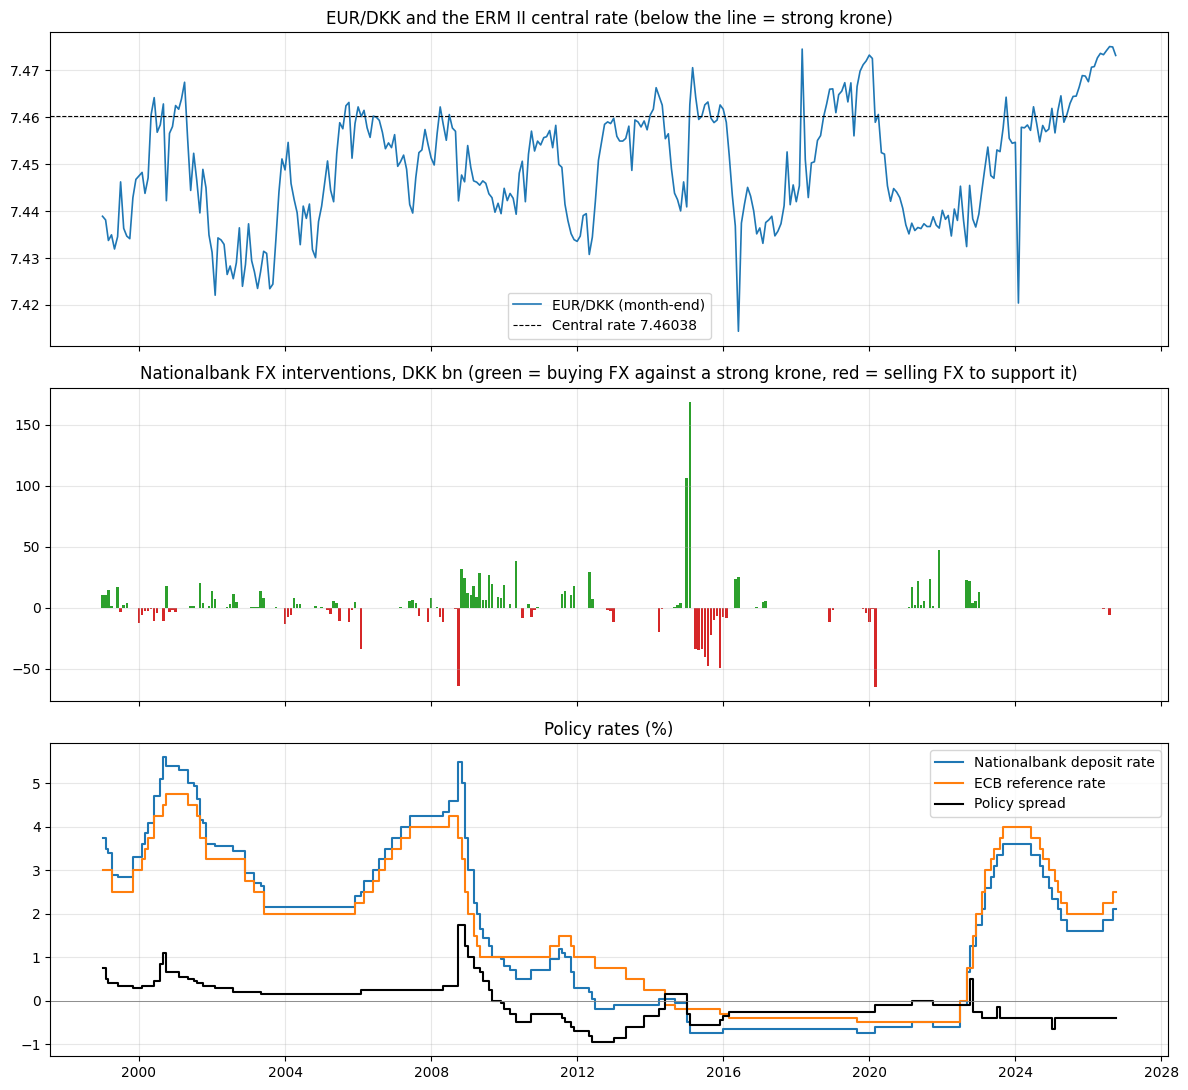

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True)
x = df.to_timestamp()
axes[0].plot(x.index, x['eurdkk'], lw=1.2, label='EUR/DKK (month-end)')
axes[0].axhline(CENTRAL_RATE, color='k', lw=0.8, ls='--', label='Central rate 7.46038')
axes[0].set_title("EUR/DKK and the ERM II central rate (below the line = strong krone)"); axes[0].legend()
axes[1].bar(x.index, x['interventions'].fillna(0), width=25,
            color=np.where(x['interventions'].fillna(0) > 0, 'tab:green', 'tab:red'))
axes[1].set_title("Nationalbank FX interventions, DKK bn (green = buying FX against a strong krone, red = selling FX to support it)")
axes[2].step(x.index, x['dn_rate'], where='post', label='Nationalbank deposit rate')
axes[2].step(x.index, x['ecb_ref'], where='post', label='ECB reference rate')
axes[2].step(x.index, x['spread'], where='post', label='Policy spread', color='k')
axes[2].axhline(0, color='grey', lw=0.6); axes[2].legend(); axes[2].set_title("Policy rates (%)")
plt.tight_layout(); plt.show()

The three panels summarise the mechanism. Periods of a strong krone (EUR/DKK below the central rate) coincide with large FX purchases, and are followed by a lower policy spread. Periods of a weak krone coincide with FX sales and a higher spread. The remaining sections test this formally.

## 3. Identifying unilateral rate moves

A unilateral move is a change in the policy spread, i.e. a Nationalbank rate change that is not matched by the ECB. It is measured on **daily** data in three steps:

1. On each day, the unilateral change is the change in the Nationalbank rate minus the change in the ECB reference rate.
2. The technical adjustment of 19 March 2021 is excluded. On that date the certificate-of-deposit rate rose from −0.60% to −0.50% while the current-account rate fell, which the Nationalbank described as leaving banks' overall interest costs broadly unchanged.
3. Short-lived deviations that are reversed are removed. The Nationalbank often implements a decision a few days before or after the ECB. For example, it raised rates by 0.60 points on 28 October 2022, while the ECB's 0.75-point increase took effect on 2 November. A level that lasts fewer than ten days and is left by a move in the opposite direction is treated as such a timing mismatch: only the persistent difference, −0.15 points, is a unilateral move. Consecutive moves in the same direction are kept as separate moves, such as the four cuts between 19 January and 5 February 2015.

Daily moves are then summed by month.

In [6]:
def unilateral_moves(df: pd.DataFrame, min_bp: float = 5.0) -> pd.Series:
    """
    Unilateral move in month t, in percentage points: the persistent change in the
    Nationalbank-ECB policy spread during month t (see daily_unilateral_moves).
    Moves smaller than `min_bp` basis points are ignored.
    """
    u = df["unilateral"].round(4)
    return u.where(u.abs() >= min_bp / 100, 0.0)


def _expanding_z(x: pd.Series, min_periods: int = 24) -> pd.Series:
    """Standardise using only past data (expanding mean and std up to t)."""
    mu = x.expanding(min_periods).mean()
    sd = x.expanding(min_periods).std()
    return (x - mu) / sd


def pressure_index(df: pd.DataFrame, min_periods: int = 24) -> pd.DataFrame:
    """
    Exchange-market pressure (EMP), in the spirit of Girton & Roper (1977) and
    Eichengreen, Rose & Wyplosz (1996), adapted to a hard peg:
        EMP_t = z(-deviation_t) + z(interventions_t)
    Positive EMP = APPRECIATION pressure on the krone (strong krone and/or the
    Nationalbank buying foreign exchange). Negative = DEPRECIATION pressure.
    Interest-rate changes are excluded because they are the outcome we want to predict.
    Standardisation is expanding, so the index uses no future information.
    """
    strength = -df["dev_pct"]
    iv = df["interventions"].fillna(0.0)
    out = pd.DataFrame({
        "z_strength": _expanding_z(strength, min_periods),
        "z_interventions": _expanding_z(iv, min_periods),
    })
    out["emp"] = out["z_strength"] + out["z_interventions"]
    return out


def event_table(df: pd.DataFrame, moves: pd.Series, emp: pd.DataFrame) -> pd.DataFrame:
    """One row per unilateral move, with the pressure readings at the end of the previous month."""
    ev = moves[moves != 0]
    rows = []
    for t, m in ev.items():
        prev = t - 1
        rows.append({
            "month": str(t),
            "direction": "hike" if m > 0 else "cut",
            "move_bp": round(m * 100),
            "spread_after_%": df.loc[t, "spread"],
            "EUR/DKK dev. t-1 (%)": df.loc[prev, "dev_pct"] if prev in df.index else np.nan,
            "interventions t-1 (DKK bn)": df.loc[prev, "interventions"] if prev in df.index else np.nan,
            "interventions t (DKK bn)": df.loc[t, "interventions"],
            "EMP t-1": emp.loc[prev, "emp"] if prev in emp.index else np.nan,
        })
    return pd.DataFrame(rows).set_index("month")

In [7]:
moves = unilateral_moves(df)
emp = pressure_index(df)
print(f"Unilateral cuts: {(moves < 0).sum()}   Unilateral hikes: {(moves > 0).sum()}\n")
events = event_table(df, moves, emp)
with pd.option_context('display.max_rows', 500, 'display.width', 200):
    display(events.round(2))

Unilateral cuts: 36   Unilateral hikes: 17



,direction,move_bp,spread_after_%,EUR/DKK dev. t-1 (%),interventions t-1 (DKK bn),interventions t (DKK bn),EMP t-1
month,,,,,,,
1999-01,cut,-20,0.750,NaN,NaN,10.800,NaN
1999-02,cut,-25,0.500,-0.290,10.800,10.200,NaN
1999-03,cut,-10,0.400,-0.300,10.200,14.400,NaN
1999-06,cut,-5,0.350,-0.380,0.000,17.000,NaN
1999-11,cut,-5,0.300,-0.350,0.000,0.000,NaN
2000-02,hike,5,0.350,-0.170,-12.800,-5.900,NaN
2000-06,hike,10,0.450,0.000,-1.300,-10.500,NaN
2000-08,hike,20,0.850,-0.050,-4.100,0.000,NaN
2000-09,cut,-5,1.100,-0.030,0.000,-10.500,NaN


The table lists every unilateral move identified in the data, with the pressure readings at the end of the preceding month. It is the empirical core of the project: each row can be checked against the Nationalbank's press releases.

## 4. An exchange-market pressure index

The index combines two standardised components:
- **Krone strength**: minus the percentage deviation of EUR/DKK from the central rate;
- **Interventions**: net purchases of foreign exchange in the month.

Both are standardised with an *expanding* window, using only data available up to each month, so the index contains no future information. Positive values indicate appreciation pressure (expected response: a cut). Negative values indicate depreciation pressure (expected response: a hike).

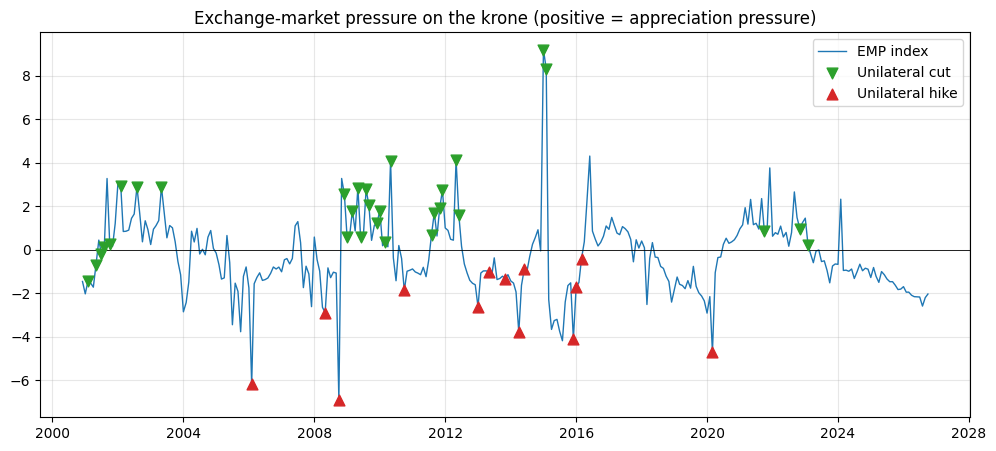

In [8]:
fig, ax = plt.subplots(figsize=(12, 5))
e = emp['emp'].to_timestamp()
ax.plot(e.index, e, lw=1, color='tab:blue', label='EMP index')
ax.axhline(0, color='k', lw=0.6)
cuts = moves[moves < 0].index.to_timestamp(); hikes = moves[moves > 0].index.to_timestamp()
ax.scatter(cuts, e.reindex(cuts), marker='v', color='tab:green', s=60, zorder=3, label='Unilateral cut')
ax.scatter(hikes, e.reindex(hikes), marker='^', color='tab:red', s=60, zorder=3, label='Unilateral hike')
ax.set_title("Exchange-market pressure on the krone (positive = appreciation pressure)"); ax.legend()
plt.show()

## 5. Does pressure predict the Nationalbank?

Four complementary tests:
1. **Event-time profile.** Average pressure in the months around unilateral cuts and hikes. If pressure predicts moves, it should build up *before* cuts (positive) and *before* hikes (negative).
2. **Predictive regression.** Next month's unilateral move on today's pressure index and policy spread, with Newey-West standard errors:
$$\text{move}_{t+1} = \alpha + \beta\,\text{EMP}_t + \gamma\,\text{spread}_t + \varepsilon_{t+1}$$
Expected signs: $\beta < 0$ (appreciation pressure leads to cuts) and $\gamma < 0$ (a spread far from zero tends to be normalised once pressure fades).
3. **Logit models** for the probability of a unilateral cut, or hike, next month.
4. **A simple warning rule.** Expect a cut (hike) within three months when EMP exceeds +k (falls below −k). *Precision* is the share of warnings followed by a move; *recall* is the share of moves preceded by a warning.

Unilateral moves are rare events, so statistical power is limited and individual episodes matter as much as aggregate statistics.

In [9]:
def event_time_profile(emp: pd.Series, moves: pd.Series, window=(-6, 3)) -> pd.DataFrame:
    """Average EMP in event time around cuts and around hikes."""
    out = {}
    for name, mask in [("cuts", moves < 0), ("hikes", moves > 0)]:
        dates = moves.index[mask]
        prof = {}
        for k in range(window[0], window[1] + 1):
            vals = [emp.get(d + k, np.nan) for d in dates]
            prof[k] = np.nanmean(vals) if len(vals) else np.nan
        out[f"{name} (n={len(dates)})"] = pd.Series(prof)
    out = pd.DataFrame(out)
    out.index.name = "months relative to move"
    return out


def predictive_regression(df: pd.DataFrame, emp: pd.Series, moves: pd.Series, lags: int = 3):
    """
    Next month's unilateral move (pp) on today's EMP and policy spread:
        move_{t+1} = a + b * EMP_t + c * spread_t + e
    Expected: b < 0 (appreciation pressure -> cut), c < 0 (a wide spread is later normalised).
    Newey-West standard errors.
    """
    import statsmodels.api as sm
    data = pd.concat([moves.shift(-1).rename("move_next"), emp.rename("EMP"),
                      df["spread"].rename("spread")], axis=1).dropna()
    X = sm.add_constant(data[["EMP", "spread"]])
    res = sm.OLS(data["move_next"], X).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return pd.DataFrame({"coef": res.params, "t-stat (NW)": res.tvalues}).assign(
        R2=res.rsquared, N=int(res.nobs))


def logit_events(emp: pd.Series, moves: pd.Series, direction: str = "cut"):
    """Probability of a unilateral cut (or hike) next month as a function of EMP today."""
    import statsmodels.api as sm
    y = (moves.shift(-1) < 0) if direction == "cut" else (moves.shift(-1) > 0)
    data = pd.concat([y.astype(float).rename("y"), emp.rename("EMP")], axis=1).dropna()
    data = data.iloc[:-1]                                       # last month has no 'next'
    try:
        res = sm.Logit(data["y"], sm.add_constant(data["EMP"])).fit(disp=0)
        return pd.Series({"coef EMP": res.params["EMP"], "t-stat": res.tvalues["EMP"],
                          "pseudo R2": res.prsquared, "events": int(data["y"].sum()),
                          "N": int(res.nobs)}), res
    except Exception as e:
        print(f"Logit for {direction}s could not be estimated: {e}")
        return pd.Series(dtype=float), None


def classification(emp: pd.Series, moves: pd.Series, thresholds=(1.0, 1.5, 2.0), horizon: int = 3):
    """
    Rule: 'expect a cut within the next `horizon` months' when EMP_t > k
          'expect a hike within the next `horizon` months' when EMP_t < -k.
    Precision = share of signals followed by a move in the predicted direction.
    Recall    = share of moves that were preceded by a signal.
    """
    rows = []
    fut_cut = pd.concat([(moves.shift(-h) < 0) for h in range(1, horizon + 1)], axis=1).any(axis=1)
    fut_hike = pd.concat([(moves.shift(-h) > 0) for h in range(1, horizon + 1)], axis=1).any(axis=1)
    past_sig = lambda sig: pd.concat([sig.shift(h, fill_value=False) for h in range(1, horizon + 1)], axis=1).any(axis=1)
    for k in thresholds:
        for name, sig, fut, mv in [("cut", emp > k, fut_cut, moves < 0), ("hike", emp < -k, fut_hike, moves > 0)]:
            n_sig = int(sig.sum())
            precision = fut[sig].mean() if n_sig else np.nan
            recall = past_sig(sig)[mv].mean() if mv.sum() else np.nan
            rows.append({"threshold": k, "direction": name, "signal months": n_sig,
                         "precision": precision, "recall": recall, "moves": int(mv.sum())})
    return pd.DataFrame(rows).set_index(["threshold", "direction"])

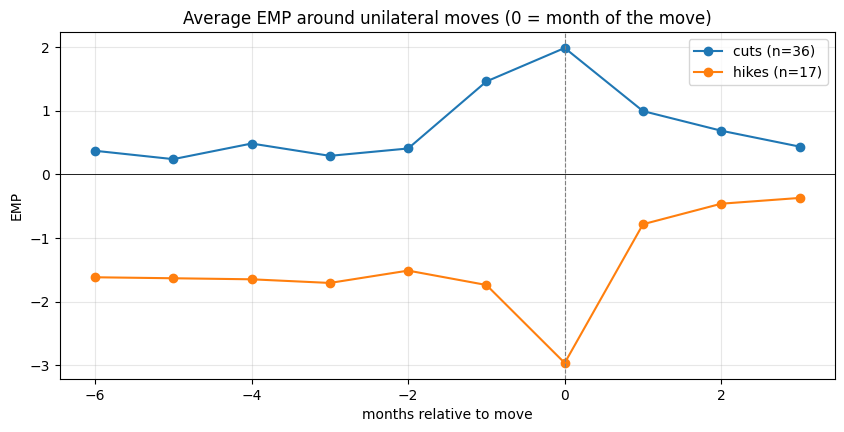

,cuts (n=36),hikes (n=17)
months relative to move,,
-6,0.370,-1.620
-5,0.240,-1.630
-4,0.490,-1.650
-3,0.290,-1.700
-2,0.410,-1.510
-1,1.460,-1.740
0,1.990,-2.960
1,1.000,-0.780
2,0.690,-0.460


In [10]:
prof = event_time_profile(emp['emp'], moves)
ax = prof.plot(marker='o', figsize=(10, 4.5))
ax.axhline(0, color='k', lw=0.6); ax.axvline(0, color='grey', ls='--', lw=0.8)
ax.set_title("Average EMP around unilateral moves (0 = month of the move)"); ax.set_ylabel("EMP")
plt.show()
display(prof.round(2))

In [11]:
print("Predictive regression: next month's unilateral move (pp)")
display(predictive_regression(df, emp['emp'], moves).round(3))
cut_stats, _ = logit_events(emp['emp'], moves, 'cut')
hike_stats, _ = logit_events(emp['emp'], moves, 'hike')
print("\nLogit: probability of a unilateral move next month")
display(pd.DataFrame({'cut': cut_stats, 'hike': hike_stats}).round(3))
print("\nWarning rule, 3-month horizon")
display(classification(emp['emp'], moves).round(2))

Predictive regression: next month's unilateral move (pp)


,coef,t-stat (NW),R2,N
const,-0.012,-1.836,0.072,310
EMP,-0.013,-4.104,0.072,310
spread,-0.035,-1.766,0.072,310



Logit: probability of a unilateral move next month


,cut,hike
coef EMP,0.608,-0.517
t-stat,4.683,-3.098
pseudo R2,0.153,0.090
events,30.000,13.000
N,310.000,310.000



Warning rule, 3-month horizon


signal months  precision  recall  moves
threshold direction                                         
1.000     cut                   54      0.480   0.580     36
          hike                 114      0.250   0.760     17
1.500     cut                   31      0.520   0.500     36
          hike                  66      0.260   0.530     17
2.000     cut                   22      0.500   0.360     36
          hike                  34      0.210   0.350     17

## 6. A stylised rates trade

A fund anticipating a unilateral cut would *receive* Danish short-term rates against euro rates, for example through a 1-year DKK-versus-EUR swap spread, and gain if the cut occurs. The stylised position is proportional to the pressure index (capped at ±1 and set to zero when |EMP| < 1), and its profit is the subsequent unilateral move times a duration of one year, in basis points.

This is deliberately simple. It measures how much of the policy-spread change was predictable from public information. It is not a realistic P&L, because market rates partly price anticipated moves before they happen (see limitations).

In [12]:
def spread_trade(emp: pd.Series, moves: pd.Series, scale: float = 2.0, band: float = 1.0) -> pd.DataFrame:
    """
    Stylised position in the DKK-EUR short-rate spread (e.g. a 1-year DKK vs EUR swap spread):
        position_t = clip(EMP_t / scale, -1, 1) if |EMP_t| > band, else 0
        P&L_{t+1}  = position_t * (-unilateral move_{t+1}) * 100     (basis points, duration = 1)
    Positive position = receive DKK / pay EUR: gains when the Nationalbank cuts unilaterally.
    This measures the predictability of policy moves. It is an upper bound on tradable
    profits, because market prices partly anticipate the moves (see limitations).
    """
    pos = (emp / scale).clip(-1, 1).where(emp.abs() > band, 0.0).fillna(0.0)
    pnl = pos.shift(1) * (-moves) * 100
    return pd.DataFrame({"position": pos, "pnl_bp": pnl.fillna(0.0)})


def current_reading(df: pd.DataFrame, emp: pd.DataFrame) -> pd.Series:
    t = df.index[-1]
    return pd.Series({
        "as_of": str(t),
        "EUR/DKK": round(df.loc[t, "eurdkk"], 4),
        "deviation from central rate (%)": round(df.loc[t, "dev_pct"], 3),
        "interventions this month (DKK bn)": df.loc[t, "interventions"],
        "Nationalbank rate (%)": df.loc[t, "dn_rate"],
        "ECB deposit rate (%)": df.loc[t, "ecb_dfr"],
        "policy spread (pp)": round(df.loc[t, "spread"], 2),
        "EMP": round(emp.loc[t, "emp"], 2),
    })

,value
Total P&L (bp),401.013
Months with a position,167.000
Unilateral moves,53.000
Moves with a position in the right direction,27.000
Moves with a position in the wrong direction,2.000


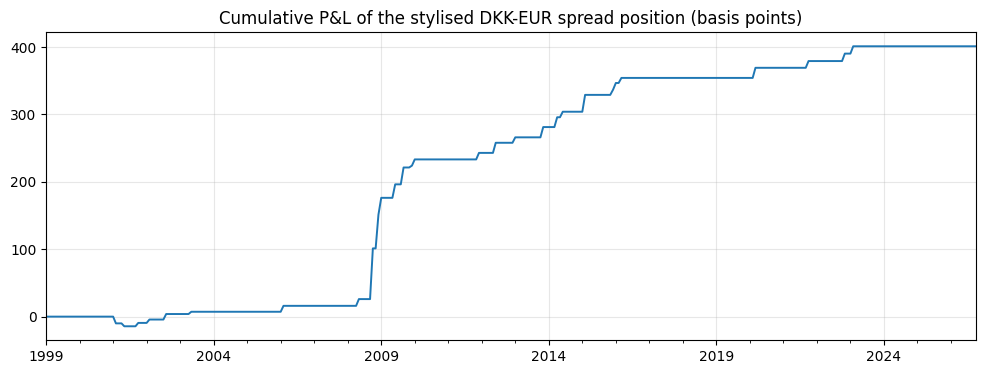


Position held going into each unilateral move:


,position held (set at t-1),move_bp,pnl_bp
1999-01,NaN,-20.000,0.000
1999-02,0.000,-25.000,0.000
1999-03,0.000,-10.000,0.000
1999-06,0.000,-5.000,0.000
1999-11,0.000,-5.000,0.000
2000-02,0.000,5.000,-0.000
2000-06,0.000,10.000,-0.000
2000-08,0.000,20.000,-0.000
2000-09,0.000,-5.000,0.000
2000-10,0.000,5.000,-0.000


In [13]:
trade = spread_trade(emp['emp'], moves)
active = trade['position'].shift(1).fillna(0) != 0
event_months = moves != 0
summary = pd.Series({
    "Total P&L (bp)": trade['pnl_bp'].sum(),
    "Months with a position": int(active.sum()),
    "Unilateral moves": int(event_months.sum()),
    "Moves with a position in the right direction": int(((trade['pnl_bp'] > 0) & event_months).sum()),
    "Moves with a position in the wrong direction": int(((trade['pnl_bp'] < 0) & event_months).sum()),
})
display(summary.to_frame('value'))
ax = trade['pnl_bp'].cumsum().to_timestamp().plot(figsize=(12, 4), lw=1.4)
ax.set_title("Cumulative P&L of the stylised DKK-EUR spread position (basis points)"); plt.show()
print("\nPosition held going into each unilateral move:")
with pd.option_context('display.max_rows', 500):
    display(pd.DataFrame({'position held (set at t-1)': trade['position'].shift(1), 'move_bp': moves * 100,
                          'pnl_bp': trade['pnl_bp']})[event_months].round(2))

## 7. Current reading

In [14]:
display(current_reading(df, emp).to_frame('value'))

,value
as_of,2026-10
EUR/DKK,7.473
deviation from central rate (%),0.172
interventions this month (DKK bn),0.000
Nationalbank rate (%),2.100
ECB deposit rate (%),2.500
policy spread (pp),-0.400
EMP,-2.040


## 8. Limitations and extensions

**Limitations**
1. **Few events.** Unilateral moves are rare, so aggregate statistics rest on a small number of episodes. The event table is as important as the regressions.
2. **Monthly frequency.** The Nationalbank often reacts within days of heavy interventions, so part of the response occurs within the same month as the pressure and cannot be predicted from month-end data.
3. **Market pricing is not modelled.** Danish money-market and swap rates partly anticipate unilateral moves. The stylised trade is therefore an upper bound on exploitable profits.
4. **Choice of ECB reference rate.** The switch from the main refinancing rate to the deposit rate in June 2014 follows the change in the effective euro money-market anchor, but other conventions are possible.
5. **Exchange-rate data.** EUR/DKK is computed from Federal Reserve noon rates in New York, not the Nationalbank's own reference rates.

**Extensions**
- Daily data around each episode, using daily interventions (`DNVALI`), which are published with a delay.
- A measure of peg credibility from the spread between Danish and euro short-term rates, following Svensson (1991).
- Market-implied expectations from DKK and EUR swap or forward rates, to measure how much of each move was priced in advance.
- The transmission of ECB policy to Denmark through the peg, as a case study of monetary policy spillovers.

## References
- Danmarks Nationalbank (2016). Effects of Danmarks Nationalbank's interventions in the foreign exchange markets. *Monetary Review*, 4th Quarter 2016.
- Eichengreen, B., Rose, A. & Wyplosz, C. (1996). Contagious currency crises: First tests. *Scandinavian Journal of Economics*.
- Girton, L. & Roper, D. (1977). A monetary model of exchange market pressure applied to the postwar Canadian experience. *American Economic Review*.
- Krugman, P. (1991). Target zones and exchange rate dynamics. *Quarterly Journal of Economics*.
- Svensson, L. (1991). The simplest test of target zone credibility. *IMF Staff Papers*.